# Import Library

In [2]:
import cv2
import os
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from skimage import filters, feature, segmentation
from scipy import ndimage

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, BatchNormalization, MaxPooling2D, GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

# Load Data Path

In [3]:
import kagglehub
path = kagglehub.dataset_download("gpiosenka/time-image-datasetclassification")

Using Colab cache for faster access to the 'time-image-datasetclassification' dataset.


In [4]:
# gabungkan semua gambar dari train/valid/test bawaan
all_paths, all_labels = [], []
for split in ["train", "valid", "test"]:
    for label_name in os.listdir(f"{path}/{split}"):
        folder = os.path.join(path, split, label_name)
        if os.path.isdir(folder):
            for img_name in os.listdir(folder):
                all_paths.append(os.path.join(folder, img_name))
                all_labels.append(label_name)

# split mandiri 80/10/10, stratify supaya 144 kelas tetap seimbang
train_paths, tmp_paths, train_labels, tmp_labels = train_test_split(
    all_paths, all_labels, test_size=0.2, stratify=all_labels, random_state=42)
val_paths, test_paths, val_labels, test_labels = train_test_split(
    tmp_paths, tmp_labels, test_size=0.5, stratify=tmp_labels, random_state=42)

In [5]:
print(f"Total data: {len(all_paths)}")
print(f"Train data: {len(train_paths)}")
print(f"Test data: {len(test_paths)}")
print(f"Validation data: {len(val_paths)}")

Total data: 14400
Train data: 11520
Test data: 1440
Validation data: 1440


# Visualisasi Data

In [6]:
def read_img(path):
    img = cv2.imread(path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (128, 128))
    return img

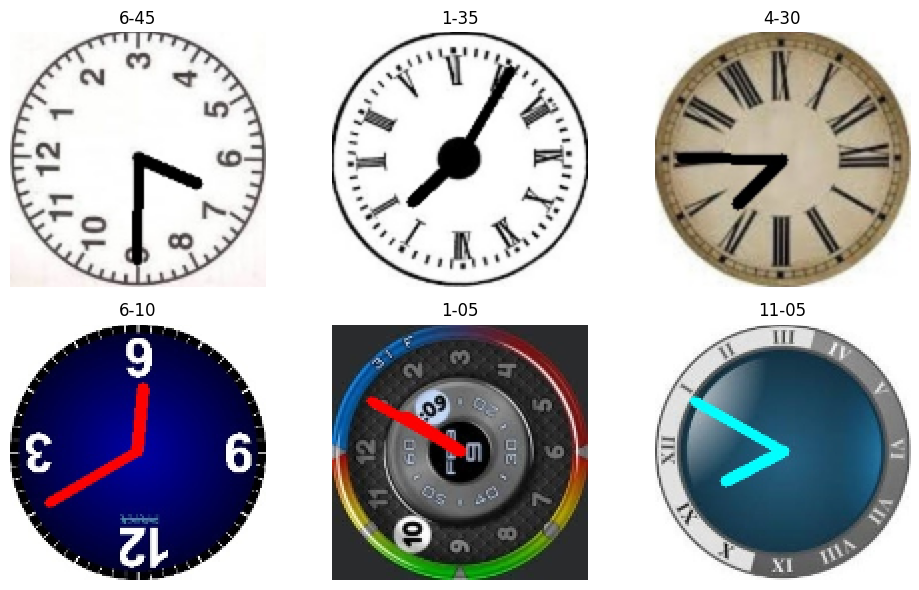

In [7]:
indices = np.random.choice(len(train_paths), 6, replace=False)
plt.figure(figsize=(10, 6))
for idx, i in enumerate(indices):
    img = read_img(train_paths[i])
    plt.subplot(2, 3, idx + 1)
    plt.imshow(img, cmap='gray')
    plt.title(train_labels[i])
    plt.axis('off')
plt.tight_layout()
plt.show()

# Label Encoding

In [8]:
all_labels = train_labels + val_labels + test_labels
le = LabelEncoder()
le.fit(all_labels)
train_labels_encoded = le.transform(train_labels)
test_labels_encoded = le.transform(test_labels)
val_labels_encoded = le.transform(val_labels)
print("Classes:", len(le.classes_))
print("First 10:", le.classes_[:10])
print("Sample:", train_labels[0], "->", train_labels_encoded[0])

Classes: 144
First 10: ['1-00' '1-05' '1-10' '1-15' '1-20' '1-25' '1-30' '1-35' '1-40' '1-45']
Sample: 2-55 -> 59


In [9]:
le.transform(['1-20'])

array([4])

# Data Augmentation

In [10]:
def save_augmented_images(paths, labels, save_dir='augmented'):
    angles = [30, 60, 90, 120, 180]
    new_paths, new_labels = list(paths), list(labels)
    os.makedirs(save_dir, exist_ok=True)
    for i, (path, label) in enumerate(zip(paths, labels)):
        img = Image.open(path).convert('L')
        for angle in angles:
            filename = f"{save_dir}/{i}_{angle}.jpg"
            img.rotate(angle).save(filename)
            new_paths.append(filename)
            new_labels.append(label)
    return new_paths, new_labels

train_paths_aug, train_labels_aug = save_augmented_images(train_paths, train_labels_encoded)
print("Sebelum:", len(train_paths))
print("Sesudah :", len(train_paths_aug))

Sebelum: 11520
Sesudah : 69120


In [11]:
def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=1)
    img = tf.image.resize(img, [128, 128])
    img = img / 222.0
    return img, label

In [12]:
train_dataset = tf.data.Dataset.from_tensor_slices((train_paths_aug, train_labels_aug))
train_dataset = (train_dataset
                 .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
                 .cache()
                 .shuffle(2000)
                 .batch(32)
                 .prefetch(tf.data.AUTOTUNE))

In [13]:
test_dataset = tf.data.Dataset.from_tensor_slices((test_paths, test_labels_encoded))
test_dataset = (test_dataset
                 .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
                 .cache()
                 .shuffle(2000)
                 .batch(32)
                 .prefetch(tf.data.AUTOTUNE))

In [14]:
val_dataset = tf.data.Dataset.from_tensor_slices((val_paths, val_labels_encoded))
val_dataset = (val_dataset
                 .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
                 .cache()
                 .shuffle(2000)
                 .batch(32)
                 .prefetch(tf.data.AUTOTUNE))

# Modeling

In [15]:
model = Sequential([
    Input(shape=(128, 128, 1)),

    Conv2D(32, (3,3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D(),

    Conv2D(64, (3,3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D(),

    Conv2D(128, (3,3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D(),

    Conv2D(256, (3,3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D(),

    GlobalAveragePooling2D(),
    Dense(512, activation='relu'),
    Dropout(0.4),
    Dense(144, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 144)            │        73,872 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 595,216 (2.27 MB)

 Trainable params: 594,256 (2.27 MB)

 Non-trainable params: 960 (3.75 KB)

In [16]:
callbacks = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    ModelCheckpoint('best_model.keras', monitor='val_accuracy', save_best_only=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6)
]

In [17]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [18]:
history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=30,
    callbacks=callbacks
)

Epoch 1/30
2160/2160 ━━━━━━━━━━━━━━━━━━━━ 74s 28ms/step - accuracy: 0.2867 - loss: 3.1092 - val_accuracy: 0.8069 - val_loss: 0.8792 - learning_rate: 0.0010
Epoch 2/30
2160/2160 ━━━━━━━━━━━━━━━━━━━━ 53s 24ms/step - accuracy: 0.8190 - loss: 0.7181 - val_accuracy: 0.9146 - val_loss: 0.3529 - learning_rate: 0.0010
Epoch 3/30
2160/2160 ━━━━━━━━━━━━━━━━━━━━ 52s 24ms/step - accuracy: 0.9009 - loss: 0.3792 - val_accuracy: 0.9403 - val_loss: 0.2193 - learning_rate: 0.0010
Epoch 4/30
2160/2160 ━━━━━━━━━━━━━━━━━━━━ 53s 24ms/step - accuracy: 0.9262 - loss: 0.2723 - val_accuracy: 0.9451 - val_loss: 0.1983 - learning_rate: 0.0010
Epoch 5/30
2160/2160 ━━━━━━━━━━━━━━━━━━━━ 52s 24ms/step - accuracy: 0.9405 - loss: 0.2164 - val_accuracy: 0.9472 - val_loss: 0.2369 - learning_rate: 0.0010
Epoch 6/30
2160/2160 ━━━━━━━━━━━━━━━━━━━━ 52s 24ms/step - accuracy: 0.9489 - loss: 0.1799 - val_accuracy: 0.9521 - val_loss: 0.1700 - learning_rate: 0.0010
Epoch 7/30
2160/2160 ━━━━━━━━━━━━━━━━━━━━ 52s 24ms/step - accura

# Evaluation

In [25]:
train_loss, train_accuracy = model.evaluate(train_dataset, verbose=0)
test_loss, test_accuracy = model.evaluate(test_dataset, verbose=0)

print(f"Train Accuracy : {train_accuracy:.4f} | Loss: {train_loss:.4f}")
print(f"Test Accuracy  : {test_accuracy:.4f} | Loss: {test_loss:.4f}")

Train Accuracy : 0.9989 | Loss: 0.0035
Test Accuracy  : 0.9875 | Loss: 0.0736


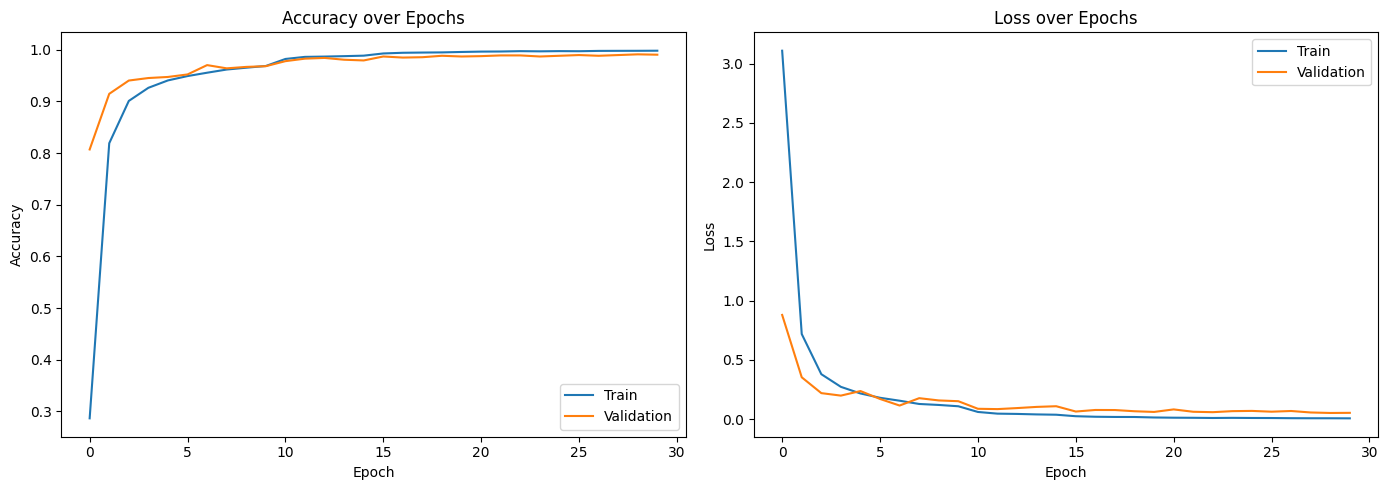

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history['accuracy'], label='Train')
axes[0].plot(history.history['val_accuracy'], label='Validation')
axes[0].set_title('Accuracy over Epochs')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()

axes[1].plot(history.history['loss'], label='Train')
axes[1].plot(history.history['val_loss'], label='Validation')
axes[1].set_title('Loss over Epochs')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()

plt.tight_layout()
plt.show()

# Saved Model

In [34]:
model.export('saved_model')  # SavedModel

with open('model.tflite', 'wb') as f:  # TF-Lite
    f.write(tf.lite.TFLiteConverter.from_saved_model('saved_model').convert())

with open('label.txt', 'w') as f:
    f.write('\n'.join(le.classes_))

Saved artifact at 'saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 128, 1), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 144), dtype=tf.float32, name=None)
Captures:
  138869567730704: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138869567732048: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138869567731280: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138869567731088: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138869567731472: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138869567729360: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138869567731664: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138869567733008: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138869567732816: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138869567732624: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138869567730896: 

In [1]:
import sys, types
sys.modules["tensorflow_decision_forests"] = types.ModuleType("tensorflow_decision_forests")

import tensorflowjs as tfjs
tfjs.converters.convert_tf_saved_model("saved_model", "tfjs_model")

2026-10-26 12:01:11.038695: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-26 12:01:11.443266: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-26 12:01:11.850175: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1792990872.107155    2750 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1792990872.186059    2750 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1792990872.839675    2750 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linkin

In [35]:
# Untuk download folder saved_model
import shutil
from google.colab import files

shutil.make_archive("saved_model", "zip", "saved_model")
files.download("saved_model.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Inference

In [36]:
loaded = tf.saved_model.load("saved_model")
infer = loaded.signatures["serving_default"]
input_name = list(infer.structured_input_signature[1].keys())[0]

def predict_batch(images):
    out = infer(**{input_name: tf.constant(images)})
    return list(out.values())[0].numpy()

# dataset test tanpa shuffle, supaya urutannya sama dengan test_paths
ds = (tf.data.Dataset.from_tensor_slices((test_paths, test_labels_encoded))
      .map(load_image).batch(64))
y_pred = np.concatenate([np.argmax(predict_batch(x), axis=1) for x, _ in ds])
print(f"Akurasi SavedModel pada test set: {(y_pred == test_labels_encoded).mean():.4f}")

Akurasi SavedModel pada test set: 0.9875


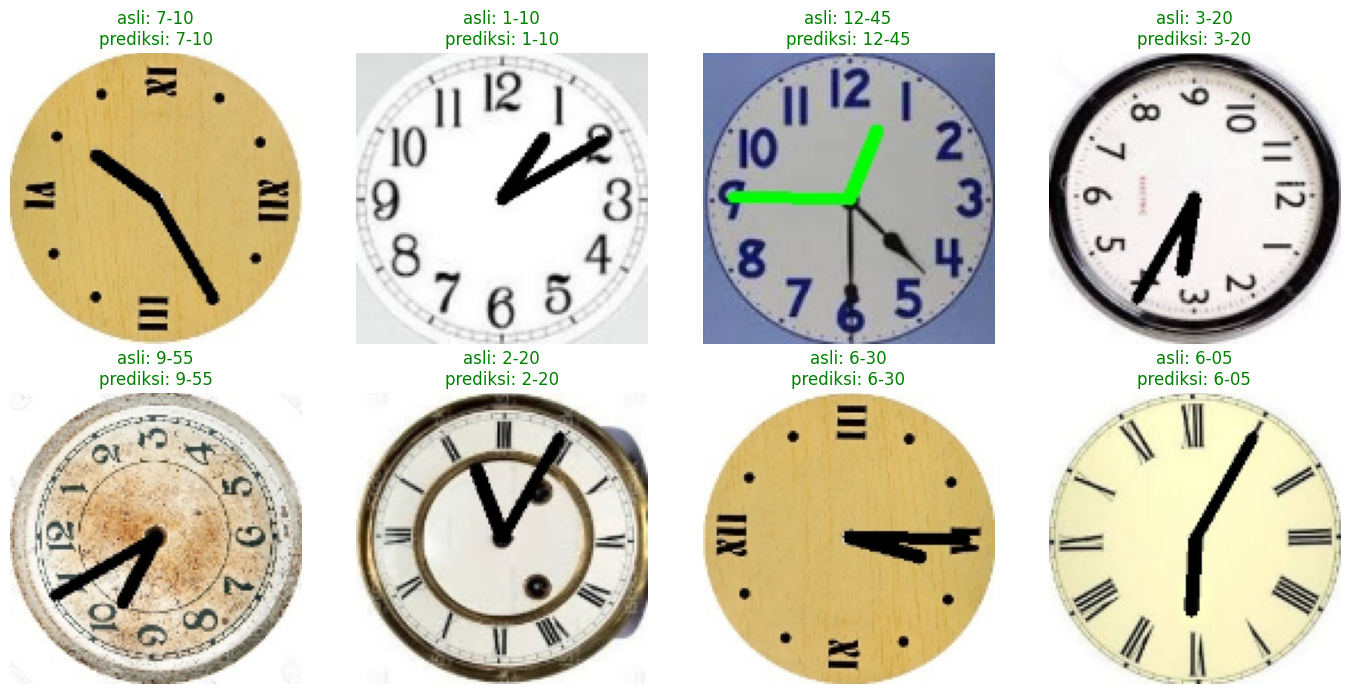

In [38]:
plt.figure(figsize=(14, 7))
for k, i in enumerate(np.random.choice(len(test_paths), 8, replace=False)):
    pred = le.classes_[y_pred[i]]
    plt.subplot(2, 4, k + 1)
    plt.imshow(read_img(test_paths[i])); plt.axis("off")
    plt.title(f"asli: {test_labels[i]}\nprediksi: {pred}",
              color="green" if pred == test_labels[i] else "red")
plt.tight_layout()
plt.show()